In [19]:
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt
import matplotlib.tri as tri
import seaborn as sb

#Training samples = 1500, #Testing samples = 500
Class distribution:
 Training:
  [0.337 0.333 0.331]
 Testing:
  [0.328 0.336 0.336]


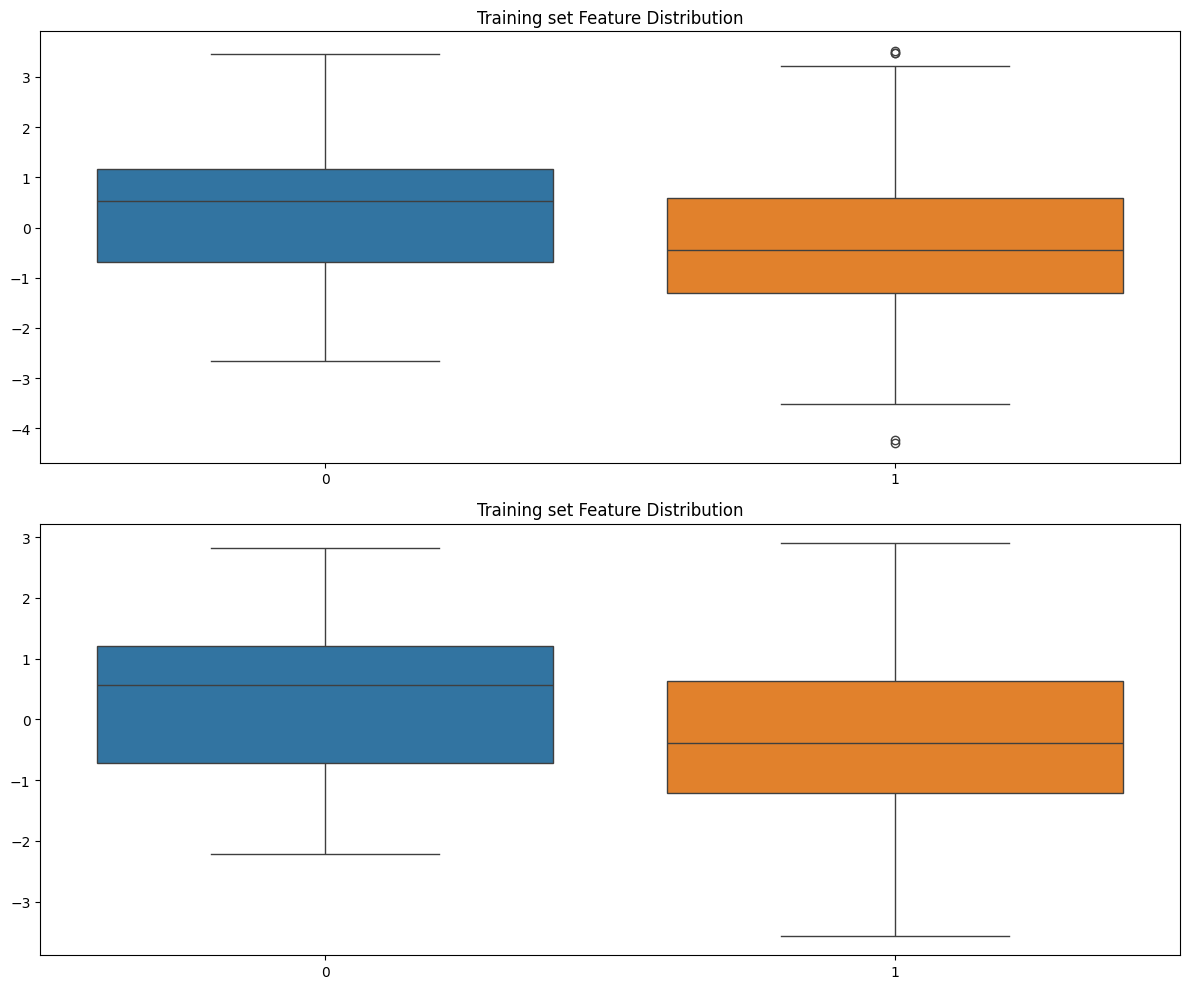

In [2]:
X, y = make_classification(
    n_samples= 2000,
    n_classes=3,
    n_clusters_per_class=1,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_repeated=0,
    random_state=42
)

x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)
print(f"#Training samples = {x_train.shape[0]}, #Testing samples = {x_test.shape[0]}")

print(f"Class distribution:\n Training:\n  {(np.unique(y_train, return_counts=True)[-1]/y_train.shape[0]).round(3)}\n Testing:\n  {(np.unique(y_test, return_counts=True)[-1]/y_test.shape[0]).round(3)}")

fig, ax = plt.subplots(2, 1, figsize=(12, 10))

sb.boxplot(data = x_train, ax=ax[0]);ax[0].set_title('Training set Feature Distribution')
sb.boxplot(data = x_test, ax=ax[1]);ax[1].set_title('Training set Feature Distribution')

plt.tight_layout()
plt.show()

In [3]:
log_r = LogisticRegression(max_iter=200, fit_intercept=False)
log_r.fit(x_train, y_train)

print(log_r.coef_, log_r.intercept_)
print(log_r.score(x_test, y_test))

[[ 1.65134205 -0.88058753]
 [ 0.49988864  1.87439812]
 [-2.15123069 -0.99381059]] [0. 0. 0.]
0.89


If sklearn really takes care of redundancy removal, then the:
- symmetric multinomial logistic transform
    - $\tilde{z}_{ik} = z_{ik} - \dfrac{1}{K}\sum\limits_{k=1}^K z_{ik}$ , s.t. $\forall \, i \, \sum\limits_{k=1}^K \tilde{z}_{ik} = 0$ , ensures logits-centering
- Given $W = \begin{bmatrix} w_{1, 1} & w_{1, 2} & w_{1, 3} & \cdots & w_{1, d} \\ w_{2, 1} & w_{2, 2} & w_{2, 3} & \cdots & w_{2, d} \\ w_{K, 1} & w_{K, 2} & w_{K, 3} & \cdots & w_{K, d}   \end{bmatrix}$
- $\sum\limits_{k=1}^K \tilde{z}_{ik} = 0 \Rightarrow \sum\limits_{k=1}^K \sum\limits_{j=1}^d w_{k, j}.x_{i,j} = \sum\limits_{j=1}^d \sum\limits_{k=1}^K w_{k, j}.x_{i,j} = \sum\limits_{j=1}^d x_{i,j} \left(\sum\limits_{k=1}^K w_{k, j}\right) $
- if its ensured that $\sum\limits_{k=1}^K w_{k, j} = 0$, then the redundancy is removed.

Hence, if sklearn obeys this condition, it can be accepted that it has implemented this redundancy removal.


In [4]:
print(log_r.coef_.T.sum(axis=1))

[-8.8817842e-16  4.4408921e-16]


Confirmed that sklearn has implemented this redundancy removal

Let's check whether the `multi_class=auto` points to `multi_class=multinomial`.

In [5]:
multinomial_log_r = LogisticRegression(max_iter=200, multi_class='multinomial', fit_intercept=False)
multinomial_log_r.fit(x_train, y_train)

print(multinomial_log_r.coef_)

[[ 1.65134205 -0.88058753]
 [ 0.49988864  1.87439812]
 [-2.15123069 -0.99381059]]


Confirmed!!

Compare predict_proba output with actual computation of the predicted probability

In [6]:
print(log_r.predict_proba(x_test[:10]))

[[2.20612840e-01 9.97304357e-02 6.79656724e-01]
 [9.66338077e-01 4.04982282e-03 2.96121002e-02]
 [6.53198798e-02 9.34572542e-01 1.07578423e-04]
 [5.81268440e-03 5.69662625e-04 9.93617653e-01]
 [9.32998315e-01 1.69614800e-03 6.53055373e-02]
 [9.83276906e-01 1.04005571e-02 6.32253656e-03]
 [9.34343950e-01 6.17161825e-03 5.94844316e-02]
 [2.29570364e-01 7.62257489e-01 8.17214644e-03]
 [4.51387473e-03 1.68891437e-01 8.26594688e-01]
 [2.02795632e-01 7.94165557e-01 3.03881019e-03]]


In [7]:
W = log_r.coef_
logits = x_test.dot(W.T)
exponents = np.exp(logits)
exponents_sum = exponents.sum(axis=1)
exponents_sum = np.broadcast_to(np.expand_dims(exponents_sum, axis=1), exponents.shape)
exponents /= exponents_sum
exponents[:10]

array([[2.20612840e-01, 9.97304357e-02, 6.79656724e-01],
       [9.66338077e-01, 4.04982282e-03, 2.96121002e-02],
       [6.53198798e-02, 9.34572542e-01, 1.07578423e-04],
       [5.81268440e-03, 5.69662625e-04, 9.93617653e-01],
       [9.32998315e-01, 1.69614800e-03, 6.53055373e-02],
       [9.83276906e-01, 1.04005571e-02, 6.32253656e-03],
       [9.34343950e-01, 6.17161825e-03, 5.94844316e-02],
       [2.29570364e-01, 7.62257489e-01, 8.17214644e-03],
       [4.51387473e-03, 1.68891437e-01, 8.26594688e-01],
       [2.02795632e-01, 7.94165557e-01, 3.03881019e-03]])

In [8]:
def label_smoothing(labels, epsilon=0.1):
    n_classes = labels.shape[1]  # Assuming labels are one-hot encoded
    smoothed_labels = (1 - epsilon) * labels + (epsilon / n_classes)
    return smoothed_labels

def multinomial_probabilities(weight_mat, x_input, return_loss = False, y_input = None):
    logits = None
    if x_input.ndim != weight_mat.ndim:
        # collection of weight matrices has been passed as input
        # weight_mat: (n_W, K, d), xip: (n, d)
        logits = np.einsum('abc,dc->adb', weight_mat, x_input)
    else:
        logits = x_input.dot(weight_mat.T)
    exponents = np.exp(logits)
    exponents_sum = exponents.sum(axis=-1)
    exponents_sum = np.broadcast_to(np.expand_dims(exponents_sum, axis=-1), exponents.shape)
    probabilities = exponents/exponents_sum
    if x_input.ndim != weight_mat.ndim:
        print(f"Logits shape = {logits.shape}, exponents_sum shape = {exponents_sum.shape},  probabilities shape = {probabilities.shape}")

    

    if return_loss:
        if y_input is None:
            raise Exception("For loss-calculation, please provide y_input as the target labels of the given input samples.")
        y_ohe = y_input.copy()
        if y_input.shape != probabilities.shape:
            # y_input is not one-hot encoded
            y_ohe = np.zeros_like(probabilities)
            y_ohe[np.arange(y_input.shape[0]), y_input] = 1
        y_ohe = label_smoothing(y_ohe)
        dx = 1e-8
        ax = None if x_input.ndim == weight_mat.ndim else tuple(range(1, weight_mat.ndim))
        loss_arr = (-(y_ohe * np.log(np.clip(probabilities, dx, 1-dx)))).sum(axis=ax)
        return probabilities, loss_arr

    return probabilities

# with adding a constant matrix to coef_
W_new = W.copy()

# initialise a row vector [c1 c2 ... cd]
# broadcast this to a matrix of shape K x d, where all rows are the same
C = np.broadcast_to(np.random.randn(W_new.shape[1]), W_new.shape)
W_new += C

print(f"W = {W}\n\nW_new = {W_new}\n")

exponents = multinomial_probabilities(W_new, x_test)
exponents[:10]

W = [[ 1.65134205 -0.88058753]
 [ 0.49988864  1.87439812]
 [-2.15123069 -0.99381059]]

W_new = [[ 0.20549084 -2.41135963]
 [-0.94596257  0.34362602]
 [-3.59708191 -2.52458269]]



array([[2.20612840e-01, 9.97304357e-02, 6.79656724e-01],
       [9.66338077e-01, 4.04982282e-03, 2.96121002e-02],
       [6.53198798e-02, 9.34572542e-01, 1.07578423e-04],
       [5.81268440e-03, 5.69662625e-04, 9.93617653e-01],
       [9.32998315e-01, 1.69614800e-03, 6.53055373e-02],
       [9.83276906e-01, 1.04005571e-02, 6.32253656e-03],
       [9.34343950e-01, 6.17161825e-03, 5.94844316e-02],
       [2.29570364e-01, 7.62257489e-01, 8.17214644e-03],
       [4.51387473e-03, 1.68891437e-01, 8.26594688e-01],
       [2.02795632e-01, 7.94165557e-01, 3.03881019e-03]])

In [9]:
_, loss = multinomial_probabilities(W_new, x_test, return_loss=True, y_input=y_test)
loss

295.2001363049113

In [10]:
y_test

array([1, 0, 1, 2, 0, 0, 0, 1, 2, 1, 2, 0, 2, 1, 1, 0, 1, 2, 0, 2, 0, 0,
       1, 1, 2, 1, 2, 2, 0, 0, 2, 2, 0, 0, 2, 1, 1, 2, 2, 2, 1, 1, 0, 1,
       2, 2, 2, 2, 2, 2, 0, 1, 0, 2, 2, 1, 0, 1, 0, 2, 2, 2, 1, 0, 1, 0,
       0, 2, 2, 1, 0, 2, 1, 2, 2, 2, 1, 2, 1, 1, 1, 2, 1, 0, 2, 0, 2, 0,
       0, 1, 1, 1, 1, 2, 0, 0, 0, 1, 2, 0, 2, 0, 1, 2, 1, 2, 2, 1, 1, 1,
       2, 0, 1, 2, 2, 0, 1, 2, 0, 1, 1, 0, 0, 0, 2, 2, 1, 0, 1, 0, 0, 1,
       1, 0, 2, 0, 0, 0, 0, 1, 1, 0, 2, 0, 1, 2, 0, 2, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 2, 2, 1, 1, 0, 1, 1, 0, 1, 2, 0, 2, 0, 2, 2, 2, 1,
       1, 1, 0, 1, 0, 1, 1, 2, 1, 0, 2, 2, 1, 1, 2, 2, 0, 1, 2, 0, 1, 2,
       1, 2, 2, 2, 1, 2, 2, 0, 1, 2, 0, 0, 1, 2, 2, 1, 1, 2, 1, 2, 2, 0,
       2, 0, 2, 2, 1, 2, 0, 1, 0, 0, 1, 2, 2, 0, 2, 0, 1, 1, 1, 1, 0, 2,
       2, 2, 1, 1, 1, 0, 1, 1, 0, 2, 0, 0, 0, 1, 0, 0, 0, 2, 0, 2, 1, 0,
       2, 2, 2, 2, 0, 0, 1, 0, 1, 1, 1, 2, 2, 1, 2, 2, 0, 1, 0, 2, 2, 0,
       0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 2, 0, 1, 2, 1,

TODO:
- create loss landscape through the following steps
    - freeze the problem, i.e. the training and test sets
    - using the most optimal weight matrix and bias vector obtained, perturb them to create a weight-matrix and bias-vector parameter space
    - find losses for each perturbed weight-matrix and bias vector obtained
    - plot loss vs parameter curve for all these 33 parameters
- since we have 6 parameters
    - even if we sample 10 values per parameter, the entire parameter space , i.e. the mesh, will be 1M points
    - instead, let's fix the parameters that are multiplied with the 2nd feature, and focus only on the parameters of the 1st feature
    - even in that, let's freeze the feature-1 logit-1 param and focus on the remaining two feature-1 related params
    - we will have 2 cases
        - case-1: no redundancy removal, hence we have 2 degrees of freedom: $w_{2, 1}\, w_{3, 1}$, and we have a 2d mesh
        - case-2: redundancy removal, hence we have only 1 degree of freedom: $w_{2, 1}$ \
            $w_{3, 1} = -(w_{1, 1} + w_{2, 1})$

In [11]:
n_samples = 1000
w21_min = W[1, 0] - 5
w21_max = W[1, 0] + 5

w21_vals = np.linspace(w21_min, w21_max, n_samples)

w31_vals_case1 = np.linspace(w21_min, w21_max, n_samples)

w31_vals_case2 = -(W[0, 0] + w21_vals)

W_case1 = W.copy()
W_case1 = np.broadcast_to(W_case1[:, :, np.newaxis], tuple(list(W_case1.shape)+[n_samples]) ).transpose(2, 0, 1).copy()
W_case1[:, 1, 0] = w21_vals
W_case1[:, 2, 0] = w31_vals_case1
probs, losses_case1 = multinomial_probabilities(W_case1, x_test, return_loss=True, y_input=y_test)
losses_case1

Logits shape = (1000, 500, 3), exponents_sum shape = (1000, 500, 3),  probabilities shape = (1000, 500, 3)


array([15.65262145,  4.91983073, 15.61477512, 15.31914706,  4.90984508,
        4.90652154,  4.90320052, 15.52017921, 15.16450169, 15.48234876,
       15.10266465,  4.88662591, 15.04083919, 15.40668833, 15.3877763 ,
        4.87340378, 15.34995603, 14.88634411,  4.86351435, 14.82457481,
        4.85693446,  4.85364845, 15.23652625, 15.21762593, 14.67022797,
       15.17982941, 14.60852126, 14.57767506,  4.83072062,  4.82745592,
       14.48516595, 14.45433967,  4.81767802,  4.81442415, 14.36189223,
       14.99093199, 14.97205037, 14.26949362, 14.23870534, 14.20792283,
       14.89653935, 14.87766553,  4.78526315, 14.83992271, 14.0541001 ,
       14.02335418, 13.9926147 , 13.96188175, 13.93115545, 13.90043589,
        4.75953269, 14.68901794,  4.75312861, 13.77762726, 13.74694304,
       14.61360719,  4.74035518, 14.57591268,  4.73398597, 13.59363542,
       13.56299742, 13.53236755, 14.48170915,  4.71811459, 14.44404121,
        4.71178688,  4.70862753, 13.34876634, 13.31819707, 14.34

In [12]:
probs[0], losses_case1[0]

(array([[1.12761915e-01, 2.10666167e-01, 6.76571918e-01],
        [9.96790718e-01, 3.37408508e-05, 3.17554159e-03],
        [9.95977417e-01, 3.98744660e-03, 3.51363995e-05],
        ...,
        [9.75837773e-01, 1.09215219e-04, 2.40530113e-02],
        [9.82193407e-01, 1.64303308e-02, 1.37626205e-03],
        [1.05843938e-03, 8.16826579e-03, 9.90773295e-01]]),
 15.652621450958106)

In [25]:
# Stack (x, y) and find unique rows
xy = np.vstack((w21_vals, w31_vals_case1)).T
xy_unique, indices = np.unique(xy, axis=0, return_index=True)

# Extract unique x, y, z values
x, y, z = xy_unique[:, 0], xy_unique[:, 1], losses_case1[indices]

print(x);print(y)

# # Triangulation
# triang = tri.Triangulation(x, y)

# # Contour plot
# plt.tricontourf(triang, z, levels=20, cmap='viridis')
# plt.colorbar(label='Loss values')
# # plt.scatter(w21_vals, w31_vals_case1, color='red', s=10)  # Show data points
# plt.show()

[-4.50011136e+00 -4.49010135e+00 -4.48009134e+00 -4.47008133e+00
 -4.46007132e+00 -4.45006131e+00 -4.44005130e+00 -4.43004129e+00
 -4.42003128e+00 -4.41002127e+00 -4.40001126e+00 -4.39000125e+00
 -4.37999124e+00 -4.36998123e+00 -4.35997122e+00 -4.34996121e+00
 -4.33995120e+00 -4.32994119e+00 -4.31993118e+00 -4.30992117e+00
 -4.29991116e+00 -4.28990115e+00 -4.27989114e+00 -4.26988113e+00
 -4.25987112e+00 -4.24986111e+00 -4.23985110e+00 -4.22984109e+00
 -4.21983108e+00 -4.20982107e+00 -4.19981106e+00 -4.18980105e+00
 -4.17979104e+00 -4.16978103e+00 -4.15977102e+00 -4.14976101e+00
 -4.13975100e+00 -4.12974099e+00 -4.11973098e+00 -4.10972097e+00
 -4.09971096e+00 -4.08970095e+00 -4.07969094e+00 -4.06968093e+00
 -4.05967092e+00 -4.04966091e+00 -4.03965090e+00 -4.02964089e+00
 -4.01963088e+00 -4.00962087e+00 -3.99961086e+00 -3.98960085e+00
 -3.97959084e+00 -3.96958083e+00 -3.95957082e+00 -3.94956081e+00
 -3.93955080e+00 -3.92954079e+00 -3.91953078e+00 -3.90952077e+00
 -3.89951076e+00 -3.88950

Logits shape = (1000, 500, 3), exponents_sum shape = (1000, 500, 3),  probabilities shape = (1000, 500, 3)


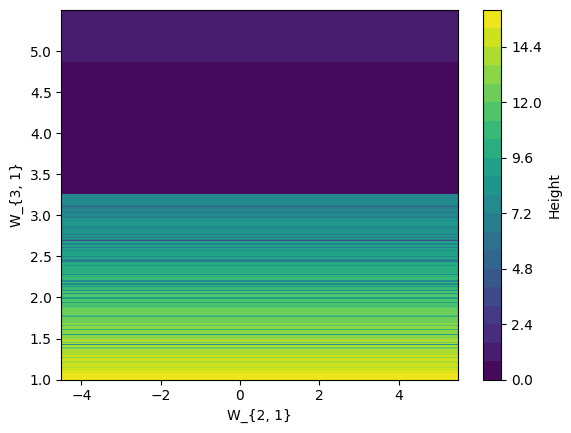

In [14]:
# plot w21 and w31 vs loss, as a contour plot
w31_vals_case1_2 = np.linspace(1, w21_max, n_samples)
W_case1_2 = W.copy()
W_case1_2 = np.broadcast_to(W_case1_2[:, :, np.newaxis], tuple(list(W_case1_2.shape)+[n_samples]) ).transpose(2, 0, 1).copy()
W_case1_2[:, 1, 0] = w21_vals
W_case1_2[:, 2, 0] = w31_vals_case1
_, losses_case1_2 = multinomial_probabilities(W_case1_2, x_test, return_loss=True, y_input=y_test)

W21_2, W31_2 = np.meshgrid(w21_vals, w31_vals_case1_2)
LOSS_C1_2 = np.broadcast_to(np.expand_dims(losses_case1_2, axis=-1), (n_samples, n_samples))

plt.contourf(W21_2, W31_2, LOSS_C1_2, cmap='viridis', levels=20)
plt.colorbar(label='Height')
plt.xlabel('W_{2, 1}');plt.ylabel('W_{3, 1}')
plt.show()

In [17]:
w21_vals

array([-4.50011136e+00, -4.49010135e+00, -4.48009134e+00, -4.47008133e+00,
       -4.46007132e+00, -4.45006131e+00, -4.44005130e+00, -4.43004129e+00,
       -4.42003128e+00, -4.41002127e+00, -4.40001126e+00, -4.39000125e+00,
       -4.37999124e+00, -4.36998123e+00, -4.35997122e+00, -4.34996121e+00,
       -4.33995120e+00, -4.32994119e+00, -4.31993118e+00, -4.30992117e+00,
       -4.29991116e+00, -4.28990115e+00, -4.27989114e+00, -4.26988113e+00,
       -4.25987112e+00, -4.24986111e+00, -4.23985110e+00, -4.22984109e+00,
       -4.21983108e+00, -4.20982107e+00, -4.19981106e+00, -4.18980105e+00,
       -4.17979104e+00, -4.16978103e+00, -4.15977102e+00, -4.14976101e+00,
       -4.13975100e+00, -4.12974099e+00, -4.11973098e+00, -4.10972097e+00,
       -4.09971096e+00, -4.08970095e+00, -4.07969094e+00, -4.06968093e+00,
       -4.05967092e+00, -4.04966091e+00, -4.03965090e+00, -4.02964089e+00,
       -4.01963088e+00, -4.00962087e+00, -3.99961086e+00, -3.98960085e+00,
       -3.97959084e+00, -

In [18]:
w31_vals_case1_2

array([1.        , 1.00450439, 1.00900879, 1.01351318, 1.01801757,
       1.02252197, 1.02702636, 1.03153075, 1.03603514, 1.04053954,
       1.04504393, 1.04954832, 1.05405272, 1.05855711, 1.0630615 ,
       1.0675659 , 1.07207029, 1.07657468, 1.08107907, 1.08558347,
       1.09008786, 1.09459225, 1.09909665, 1.10360104, 1.10810543,
       1.11260983, 1.11711422, 1.12161861, 1.126123  , 1.1306274 ,
       1.13513179, 1.13963618, 1.14414058, 1.14864497, 1.15314936,
       1.15765376, 1.16215815, 1.16666254, 1.17116694, 1.17567133,
       1.18017572, 1.18468011, 1.18918451, 1.1936889 , 1.19819329,
       1.20269769, 1.20720208, 1.21170647, 1.21621087, 1.22071526,
       1.22521965, 1.22972404, 1.23422844, 1.23873283, 1.24323722,
       1.24774162, 1.25224601, 1.2567504 , 1.2612548 , 1.26575919,
       1.27026358, 1.27476798, 1.27927237, 1.28377676, 1.28828115,
       1.29278555, 1.29728994, 1.30179433, 1.30629873, 1.31080312,
       1.31530751, 1.31981191, 1.3243163 , 1.32882069, 1.33332

In [16]:
losses_case1_2.shape, losses_case1_2

((1000,),
 array([15.65262145,  4.91983073, 15.61477512, 15.31914706,  4.90984508,
         4.90652154,  4.90320052, 15.52017921, 15.16450169, 15.48234876,
        15.10266465,  4.88662591, 15.04083919, 15.40668833, 15.3877763 ,
         4.87340378, 15.34995603, 14.88634411,  4.86351435, 14.82457481,
         4.85693446,  4.85364845, 15.23652625, 15.21762593, 14.67022797,
        15.17982941, 14.60852126, 14.57767506,  4.83072062,  4.82745592,
        14.48516595, 14.45433967,  4.81767802,  4.81442415, 14.36189223,
        14.99093199, 14.97205037, 14.26949362, 14.23870534, 14.20792283,
        14.89653935, 14.87766553,  4.78526315, 14.83992271, 14.0541001 ,
        14.02335418, 13.9926147 , 13.96188175, 13.93115545, 13.90043589,
         4.75953269, 14.68901794,  4.75312861, 13.77762726, 13.74694304,
        14.61360719,  4.74035518, 14.57591268,  4.73398597, 13.59363542,
        13.56299742, 13.53236755, 14.48170915,  4.71811459, 14.44404121,
         4.71178688,  4.70862753, 13.3487

In [238]:
y_test

array([1, 0, 1, 2, 0, 0, 0, 1, 2, 1, 2, 0, 2, 1, 1, 0, 1, 2, 0, 2, 0, 0,
       1, 1, 2, 1, 2, 2, 0, 0, 2, 2, 0, 0, 2, 1, 1, 2, 2, 2, 1, 1, 0, 1,
       2, 2, 2, 2, 2, 2, 0, 1, 0, 2, 2, 1, 0, 1, 0, 2, 2, 2, 1, 0, 1, 0,
       0, 2, 2, 1, 0, 2, 1, 2, 2, 2, 1, 2, 1, 1, 1, 2, 1, 0, 2, 0, 2, 0,
       0, 1, 1, 1, 1, 2, 0, 0, 0, 1, 2, 0, 2, 0, 1, 2, 1, 2, 2, 1, 1, 1,
       2, 0, 1, 2, 2, 0, 1, 2, 0, 1, 1, 0, 0, 0, 2, 2, 1, 0, 1, 0, 0, 1,
       1, 0, 2, 0, 0, 0, 0, 1, 1, 0, 2, 0, 1, 2, 0, 2, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 2, 2, 1, 1, 0, 1, 1, 0, 1, 2, 0, 2, 0, 2, 2, 2, 1,
       1, 1, 0, 1, 0, 1, 1, 2, 1, 0, 2, 2, 1, 1, 2, 2, 0, 1, 2, 0, 1, 2,
       1, 2, 2, 2, 1, 2, 2, 0, 1, 2, 0, 0, 1, 2, 2, 1, 1, 2, 1, 2, 2, 0,
       2, 0, 2, 2, 1, 2, 0, 1, 0, 0, 1, 2, 2, 0, 2, 0, 1, 1, 1, 1, 0, 2,
       2, 2, 1, 1, 1, 0, 1, 1, 0, 2, 0, 0, 0, 1, 0, 0, 0, 2, 0, 2, 1, 0,
       2, 2, 2, 2, 0, 0, 1, 0, 1, 1, 1, 2, 2, 1, 2, 2, 0, 1, 0, 2, 2, 0,
       0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 2, 0, 1, 2, 1,

In [265]:
indices = np.argwhere((W_case1[:, 2, 0] >= 3.5 ))
idx = indices[0]
# W_case1[idx, :, :][0]
print(losses_case1[idx])
print(multinomial_probabilities(W_case1[idx], x_test))

[0.72987945]
Logits shape = (1, 500, 3), exponents_sum shape = (1, 500, 3),  probabilities shape = (1, 500, 3)
[[[5.52241898e-01 1.06315863e-01 3.41442238e-01]
  [1.21402205e-01 9.23715428e-03 8.69360641e-01]
  [5.04474296e-04 9.90765147e-01 8.73037899e-03]
  ...
  [1.97917252e-01 3.62547892e-03 7.98457269e-01]
  [1.19409820e-02 9.11692465e-01 7.63665535e-02]
  [8.59372277e-01 1.14990172e-03 1.39477822e-01]]]
